# Визуелизација на регресија, спуштање по градиент и нормализација
### 🔴Оваа дигитална тетратка е наменета за анализа на сликите кои се генерирани од кодот, а не за анализа на самиот код 🔴
### Анализа на кодот е препорачана само за ентузијасти
Во ова дигитална тетратка ќе бидат претставени некои визуелни примери кои ќе помогнат полесно да се разберат концептите на:
* Линеарна регресија и полиномна регресија
* Оптимизација на модели на линеарна регресија со помош на алгоритам на спуштање по градиент (Gradient Descent)
* Нормализација на податочно множество и кои се придобивките од истата

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym
%matplotlib inline

# Визуелизација на спуштање по градиент 

Во рамките на овој пример ќе претставиме како еден модел на линеарна регресија се оптимизира со помош на GD алгоритамот и притоа го подобрува предвидувањето, односно ја намалува грешката.

### Најпрво ќе креираме случајно генерирано податочно множество на кое ќе го тренираме нашиот модел

1. По случаен избор генерираме 20 податочни точки од влезната величина $x$ во интервалот [0, 1.0].
2. Генерираме податочни точки од излезната величина $y$ според функцијата $y = 3x$ и дополнително додаваме гаусов шум со средна вредност 0 и стандардна девијација 0.9. Шумот го додаваме со цел да го доловиме примерот со реалноста.
3. Замислете си како величината $x$ да претставува плоштина на куќа, а величината $y$ да ја претставува цената на куќата.
4. Нашата цел е да истренираме модел на линеарна регресија од даденото податочно множество со цел да ја предвидиме "цената на куќата", според дадена плоштина која не припаѓа во нашето податочно множество.

In [15]:
m = 20
X = np.random.random(m)
error = np.random.normal(0, 0.9, m)
y = 3*X + error

### Податочното множество претставено на график

<function matplotlib.pyplot.show(close=None, block=None)>

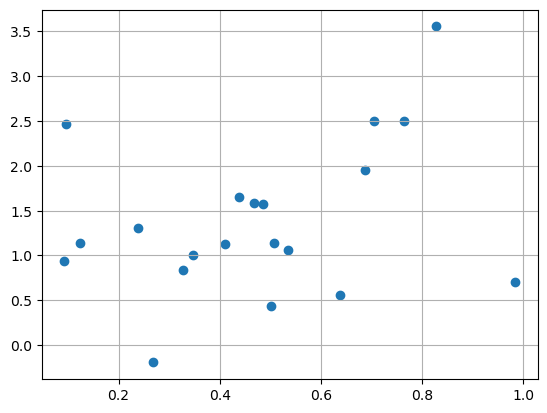

In [16]:
plt.scatter(X, y)
plt.grid()
plt.show

### Најпрво ги изразуваме функцијата на цена и нејзиниот извод како симболички израз
За симболичка математика во python можете подетално да прочитате на следниот линк:
https://scipy-lectures.org/packages/sympy.html

1. Ги дефинираме $x$, $\theta_1$ како симболички променливи
2. Моделот на предвидување кој ќе го користиме е $h_{\theta}(x) = \theta_0 + \theta_1x$
3. Функцијата на цена ја пресметуваме како $J(\theta_0, \theta_1) = \frac{1}{2m}\sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2$
4. Моделот на линеарна регресија ќе предвидува најдобро доколку ги најдеме вредностите $\theta_0, \theta_1$ за кои функцијата на цена $J(\theta_0, \theta_1)$ има најниска вредност. Односно да го најдеме нејзиниот минимум.
5. Во овој случај со цел да можеме полесно да ја визуелизираме функцијата на цена (во 2Д простор), проблемот е направен едноставен така што може да се земе $\theta_0 = 0$. Причината за ова е бидејќи функцијата $y = 3x$ не содржи слободен член.


In [17]:
x, theta_1 = sym.symbols('x, theta_1')
temp_list = y.shape[0]*[theta_1*x]
temp_list = [temp.subs(x, X[i]) for i, temp in enumerate(temp_list)]
ar = sym.Array([y.tolist(), temp_list])
J = ar[0, :] - ar[1, :]
J = sum(J)
J = J**2
J_deriv = sym.diff(J, theta_1)
theta_1_optimal = float(sym.solvers.solve(J_deriv)[0])
print("Cost f_costfunction: ", J, "\nDerivative of_cost cost f_costunction: ", J_deriv)

Cost f_costfunction:  (27.8361595706791 - 9.44627268079709*theta_1)**2 
Derivative of_cost cost f_costunction:  178.464135119947*theta_1 - 525.89590738163


### Визуелизација при тренирање на еден модел на линеарна регресија 

1. Дефинираме alpha параметар кој ќе ја дефинира големината на чекорот со кој ќе се спуштаме според градиентот
2. Дефинираме број на итерации iterations кои ќе се визуелизираат при тренирање на моделот

Применете ги различни вредности за alpha и проверете дали алгоритмот ќе конвергира и дали при конвергирање ја надминува оптималната точка. Пр. за различни вредности: 0.005, 0.005, 0.01, 0.012, 0.011

1. На левиот график е прикажан моделот на предвидување (линеарна регресија) со црвена линија истрениран во i-tata итерација
2. На десниот график е прикажана функцијата на цена за различни вредности на $\theta$
3. Во секоја итерација на тренирање го ажурираме коефициентот $\theta_1$. Различни вредности за $\theta_1$ резултираат во различни вредности на функцијата на цена, обележани со црвена точка.
4. $\theta_1$ воедно го претставува коефициентот на правец на правата генерирана од моделот на линеарна регресија.

Iteration:  1 
Cost function value:  1389.97975458592 
Cost function derivative value:  -704.360042501577 
theta_1 value:  -1


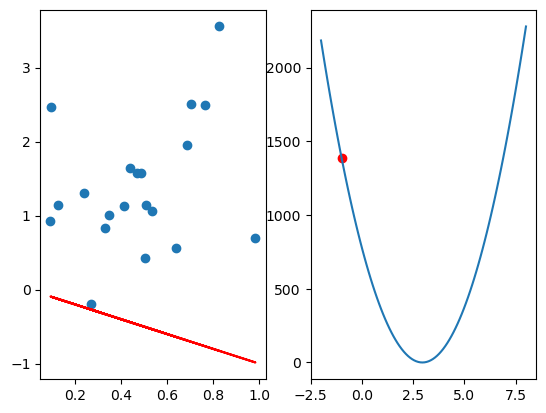

Iteration:  2 
Cost function value:  1289.30654802936 
Cost function derivative value:  678.373021277446 
theta_1 value:  6.74796046751734


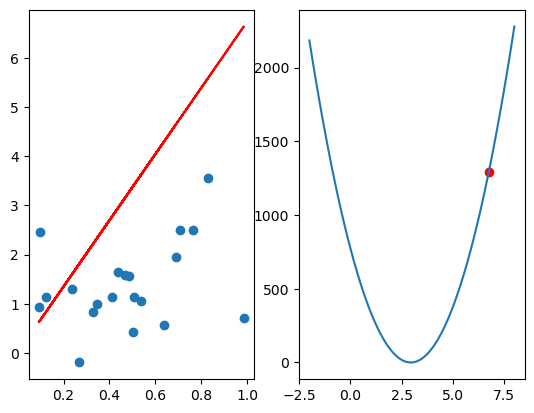

Iteration:  3 
Cost function value:  1195.92488257976 
Cost function derivative value:  -653.344778563387 
theta_1 value:  -0.714142766534561


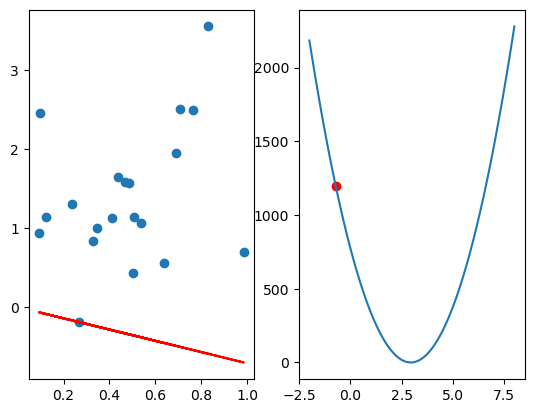

Iteration:  4 
Cost function value:  1109.30664779407 
Cost function derivative value:  629.239940692542 
theta_1 value:  6.47264979766269


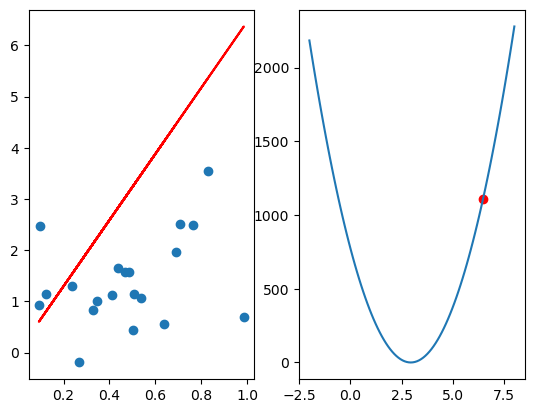

Iteration:  5 
Cost function value:  1028.96198311858 
Cost function derivative value:  -606.024439092291 
theta_1 value:  -0.448989549955270


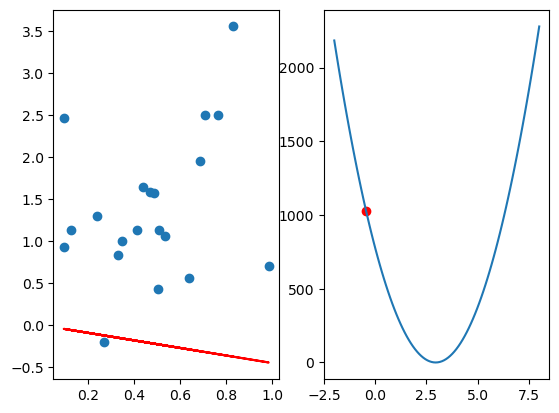

Iteration:  6 
Cost function value:  954.436507532648 
Cost function derivative value:  583.665462133433 
theta_1 value:  6.21727928005993


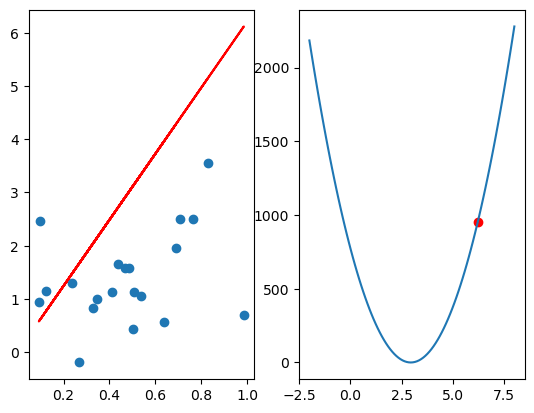

Iteration:  7 
Cost function value:  885.308749843422 
Cost function derivative value:  -562.131408755867 
theta_1 value:  -0.203040803407827


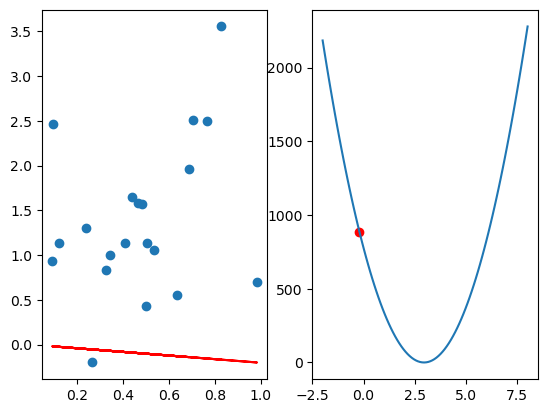

Iteration:  8 
Cost function value:  821.187765098677 
Cost function derivative value:  541.391843805238 
theta_1 value:  5.98040469290671


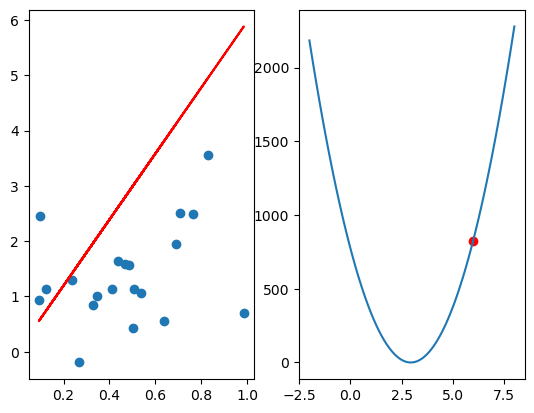

Iteration:  9 
Cost function value:  761.710923637688 
Cost function derivative value:  -521.417455017409 
theta_1 value:  0.0250944110490918


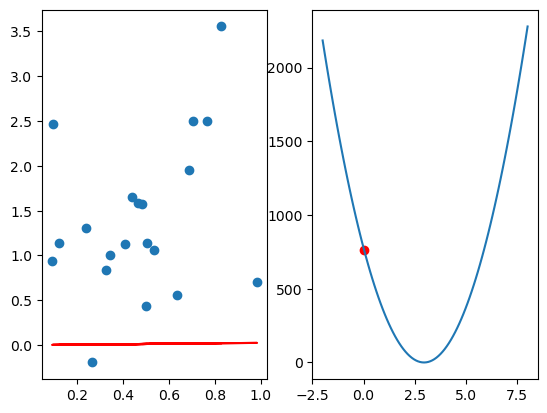

Iteration:  10 
Cost function value:  706.541860276329 
Cost function derivative value:  502.180011589974 
theta_1 value:  5.76068641624059


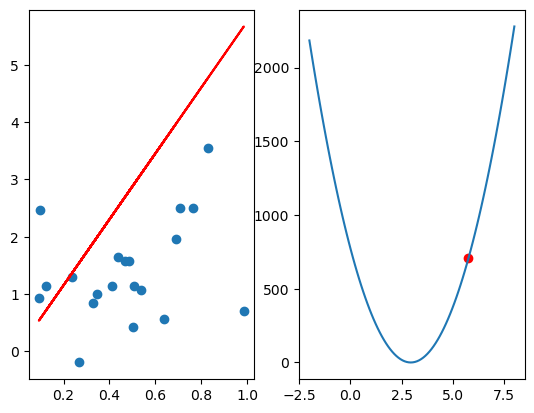

In [18]:
theta_1_trial = -1
deriv = J_deriv.subs(theta_1, theta_1_trial)
i = 0
theta_1_range = np.linspace(-2, 8, 100)
J_range = [J.subs(theta_1, theta_1_range[i]) for i, temp in enumerate(theta_1_range)]
iterations = 10
alpha = 0.011 # 0.005, 0.001, 0.01

while i < iterations:
    print("Iteration: ", i+1, "\nCost function value: ", J.subs(theta_1, theta_1_trial), "\nCost function derivative value: ", deriv, "\ntheta_1 value: ", theta_1_trial)
    plt.subplot(121)
    plt.scatter(X, y)
    plt.plot(X, X*theta_1_trial, c='r')
    
    plt.subplot(122)
    plt.plot(theta_1_range, J_range)
    plt.scatter(theta_1_trial, float(J.subs(theta_1, theta_1_trial)), c='r')
    plt.show()

    # Gradient Descent
    theta_1_trial = theta_1_trial - alpha*deriv
    deriv = J_deriv.subs(theta_1, theta_1_trial)
    i += 1


# Полиномна регресија

Доколку имаме само една карактеристика(feature) на проблемот, а истиот не е линеарен, возможно е да истренираме полиномен модел на регресија.

За да го направиме ова креаираме нови карактеристики така што $x_1 = x$, $x_2 = x^2$, $x_3 = 3$, ... ,$x_n = x^n$, за полином од $n$-ти ред.

За оваа намена ќе имплементираме две функции:
1. ComputeCost(X, y, theta) која ја пресметува функцијата на цена за различни вредности на $\theta$ векторот.
2. gradientDescent(X, y, theta, alpha, iters) примена на Gradient Descent со чекор alpha и максимум iter итерации.

In [21]:
def computeCost(X, y, theta):           # calculate cost function value
    inner = np.power(((X * theta.T) - y), 2)
    return np.sum(inner) / (2 * len(X))

def gradientDescent(X, y, theta, alpha, iters):
    temp = np.matrix(np.zeros(theta.shape))
    parameters = int(theta.ravel().shape[1])
    cost = np.zeros(iters)
    
    for i in range(iters):              # in every iteration
        error = (X * theta.T) - y       # compute the error
        
        for j in range(parameters):     # for every parameter update the value
            term = np.multiply(error, X[:,j])
            temp[0,j] = theta[0,j] - ((alpha / len(X)) * np.sum(term))
            
        theta = temp
        cost[i] = computeCost(X, y, theta)
        
    return theta, cost                  # returns theta vector and history of the cost value

### Генерираме податочно множество кое ќе биде претставено со полином од 3-ти ред

In [22]:
m = 100
X = -2*np.random.random(m) + 2*np.random.random(m)
y = 3*X**3 + 5*X**2 + 10 + np.random.normal(0, 1, m)

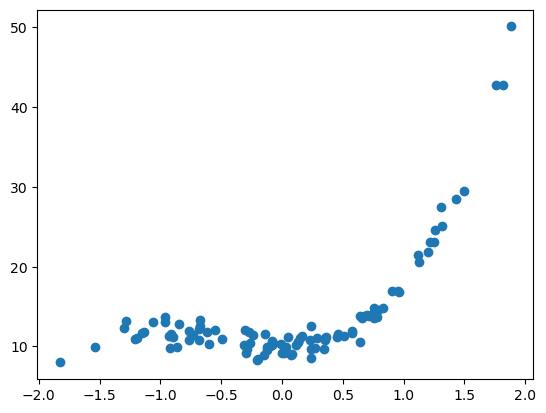

In [23]:
plt.scatter(X, y)

1. Ги вметнување сите карактеристики во X_novo кои ќе го дефинираат редот на полиномот
2. Применуваме Gradient Descent за да ги најдеме оптималните вредности за $\theta$
3. Ја исцртуваме кривата на предвидување со помош на пронајдените вредности за $\theta$

Доколку имавме само (X, np.ones(m)) во X_novo тогаш ќе имавме линеарна регресија. Обидете се да видите како ќе изгледа моделот во тој случај.

In [24]:
X_novo = np.vstack((X**3, X**2, X, np.ones(m))).T
theta, cost = gradientDescent(np.matrix(X_novo), np.matrix(y).T, np.matrix(np.array([1, 1, 1, 1])), 0.1, 1000)

In [25]:
theta

matrix([[ 3.1317421 ,  4.9560023 , -0.15564996, 10.04353272]])

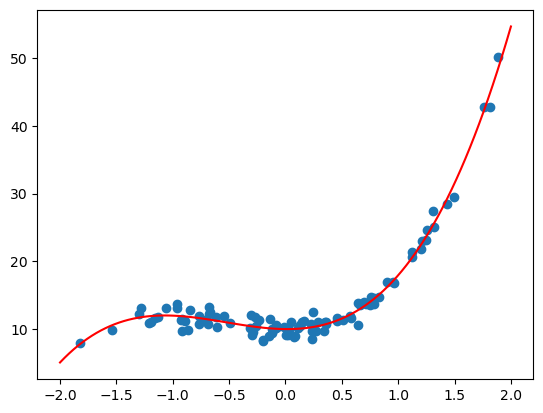

In [26]:
plt.scatter(X, y)
x_range = np.linspace(-2, 2, 100)
x_novo = np.vstack((x_range**3, x_range**2, x_range, np.ones(m))).T
y_predict = np.ravel(x_novo.dot(theta.T))
plt.plot(x_range, y_predict, 'r')

# Нормализација на податочно множество

Во овој дел ќе визуелизираме како напредува алгоритамот на Gradient Descent  во два случаи кога:
1. Податочното множество не е нормализирано
2. Податочното множество не е нормалзирано

Ќе искористиме стандардна нормализација со помош на библиотеката sklearn.

На графиците е прикажано функцијата на цена во 2Д простор каде $x$ оска e $\theta_0$, $y$ оска е $\theta_1$, бојата ја претставува вредноста на функцијата на цена каде:
* сина боја -> ниска вредност
* црвена боја -> висока вредност

Со "X" симболот се означени чекорите на Gradient Descent алгоритамот.

In [27]:
def gradientDescent(X, y, theta, alpha, iters):
    temp = theta
    for i in range(iters):              # in every iteration
        temp = (temp - alpha*X.T.dot((X.dot(temp)) - y))
        yield temp

In [28]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
m = 100
x1 = np.random.rand(m, 1)*2
x2 = np.random.rand(m, 1)
X = np.hstack((x1, x2, np.ones((m, 1))))
#X = sc.fit_transform(X)
theta_real = np.array([[2, 3, 1]]).T
y = X.dot(theta_real) + np.random.normal(0, 0.2, m).reshape(m, 1)

### Визуелизација без нормализација на податоците

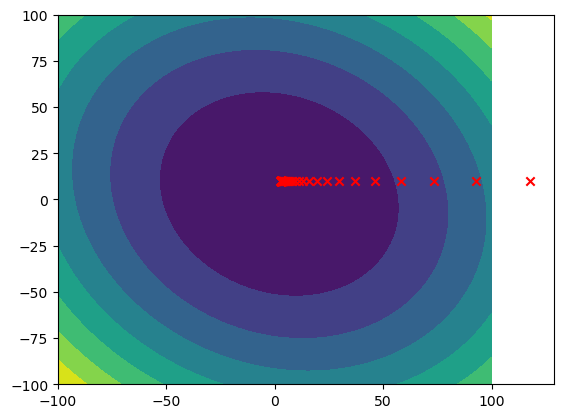

In [32]:
mx = 500
my = 500
theta1 = np.linspace(-100, 100, mx)
theta2 = np.linspace(-100, 100, my)
Theta1, Theta2 = np.meshgrid(theta1, theta2)
J = np.zeros((mx, my))
for i in range(mx):
    for j in range(my):
        pom = np.array([[Theta1[i, j], Theta2[i, j], 1]]).T
        J[i, j] = (1/(2*m)*(X.dot(pom) - y).T.dot(X.dot(pom) - y))[0, 0]
plt.contourf(Theta1, Theta2, np.array(J))
for th in gradientDescent(np.matrix(X), np.matrix(y), 10*np.matrix(np.array([[10, 15, 1]]).T), 2e-3, 100):
    plt.scatter(th[1, 0], th[2, 0], marker='x', c='r')

Од графикот може да се забележи дека функцијата има форма на сплескано ѕвоно. Поради матеиматика според која функционира Gradient Descent, истиот најпрво ќе се движи по пострмните делови. Доколку податоците не се нормализирани можеме да забележиме дека најстрмниот дел од функцијата не  не води кон оптималната точка.

Ова значи дека ќе ни бидат потребни повеќе чекори за да стигнеме до оптималната точка, односно подолго време ќе се тренира моделот.

### Визуелизација со нормализација на податоците

In [30]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
m = 100
x1 = np.random.rand(m, 1)*2
x2 = np.random.rand(m, 1)
X = np.hstack((x1, x2, np.ones((m, 1))))
X = sc.fit_transform(X)
theta_real = np.array([[2, 3, 1]]).T
y = X.dot(theta_real) + np.random.normal(0, 0.2, m).reshape(m, 1)

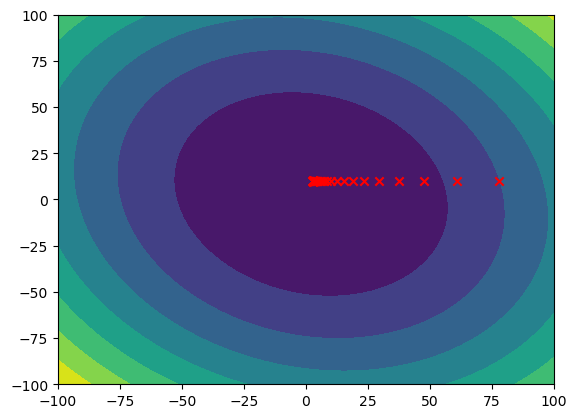

In [31]:
mx = 500
my = 500
theta1 = np.linspace(-100, 100, mx)
theta2 = np.linspace(-100, 100, my)
Theta1, Theta2 = np.meshgrid(theta1, theta2)
J = np.zeros((mx, my))
for i in range(mx):
    for j in range(my):
        pom = np.array([[Theta1[i, j], Theta2[i, j], 1]]).T
        J[i, j] = (1/(2*m)*(X.dot(pom) - y).T.dot(X.dot(pom) - y))[0, 0]
plt.contourf(Theta1, Theta2, np.array(J))
for th in gradientDescent(np.matrix(X), np.matrix(y), 10*np.matrix(np.array([[10, 10, 1]]).T), 2e-3, 100):
    plt.scatter(th[1, 0], th[2, 0], marker='x', c='r')

Во овој случај можеме да видиме дека функцијата на цена има форма на идеално ѕвоно, а алгоритамот се движи кон оптималната точка уште од самиот почеток. Според тоа тренирањето на моделот ќе се изврши во помалку чекори и за пократко време.

### Заклучок
Според тоа можеме да заклучиме дека нормализацијата на податоците ни помага во тоа да добиеме прецизен модел при тренирање за пократко време.

Доколку податоците не се нормализирани, возможно е да се добие истиот модел како и кога би биле нормализирани, но истото би побарало подолго време за тренирање